# Do seasonal patterns improve WTI crude oil return forecasts in high-volatility periods?

**Target:** `ret_CL1`, the monthly log return of the front-month WTI futures contract (CL1).
**Question:** do historical seasonal patterns (Summer/Winter, calendar months) make OLS forecasts of `ret_CL1` more accurate, specifically in **high-volatility months**?

The notebook has three steps:

| Step | What it does | Why |
|---|---|---|
| **1. Feature selection** | Picks the base OLS predictors using only the training period (1998–2010) | Gives the seasonal terms a sensible base model to add to, without using future data |
| **2. Seasonal tests** | Adds seasonal and season × volatility terms to the base model; tests them in-sample and out-of-sample | Answers the research question directly |
| **3. Seasonal-only check** | Tests seasonal terms on their own against a historical-mean forecast | Checks the result doesn't depend on the macro base model |

**Data notes:** all predictors are prefixed `L1_` and lagged one month, so everything used to forecast month *t* was known at the end of month *t−1*. `L1_HighVol = 1` when last month's VIX was above `L1_VIX_threshold` (a time-varying cutoff). `Summer` = May–Sep, `Winter` = Nov–Mar, and the month dummies use January as the baseline.

## 0. Setup

In [8]:
import warnings
import numpy as np
import pandas as pd
import statsmodels.api as sm
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.linear_model import LassoCV
from sklearn.model_selection import TimeSeriesSplit
from sklearn.preprocessing import StandardScaler
from statsmodels.stats.outliers_influence import variance_inflation_factor as vif

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 30, "display.precision", 4)

# ---------------- settings: change these to rerun the study ----------------
DATA_PATH = "model_ready_dataset.xlsx"       # the dataset, in the same folder as this notebook
TARGET    = "ret_CL1"
TRAIN_END = pd.Timestamp("2010-12-31")       # feature selection uses data up to here only
OOS_START = pd.Timestamp("2011-01-31")       # first out-of-sample forecast month
HAC       = dict(cov_type="HAC", cov_kwds={"maxlags": 3})   # Newey-West SEs (autocorrelation/heteroskedasticity robust)
P_KEEP    = 0.10                              # p-value threshold for backward elimination

In [9]:
d = pd.read_excel(DATA_PATH, sheet_name=0).sort_values("Date").reset_index(drop=True)
print(f"{d.shape[0]} months x {d.shape[1]} columns, {d.Date.min().date()} to {d.Date.max().date()}, missing values: {d.isna().sum().sum()}")

# Sanity check: the HighVol flag must be exactly "last month's VIX above the threshold"
assert ((d.L1_VIX_level > d.L1_VIX_threshold).astype(int) == d.L1_HighVol).all()

d.groupby("L1_HighVol")[TARGET].agg(["count", "mean", "std"]).rename(index={0: "LowVol", 1: "HighVol"})

319 months x 50 columns, 1997-12-31 to 2024-06-30, missing values: 0


,count,mean,std
L1_HighVol,,,
LowVol,224,0.0046,0.0849
HighVol,95,0.0044,0.1558


Average returns are almost the same in both regimes, but **volatility is nearly twice as high** in high-vol months. That makes it harder to find any predictable signal in exactly the months we care about.

---
## Step 1 — Selecting the base features

**Rules:**
1. **Training data only (≤ 2010).** Choosing features on the full sample would leak future information into the out-of-sample test.
2. **Seasonal and regime variables are left out of the candidate pool.** They are what we're testing in Step 2, so they shouldn't be chosen or discarded here. `L1_VIX_threshold` is also dropped, because it's only the cutoff used to build the high-vol flag.
3. Four checks are applied in sequence: (a) one-predictor-at-a-time screen with HAC t-stats, (b) collinearity check, (c) LASSO tuned by time-series cross-validation, (d) backward elimination with HAC p-values, followed by a variance-inflation (VIF) check.

In [10]:
SEASONAL = (["Summer", "Winter", "L1_HighVol", "Summer_x_HighVol", "Winter_x_HighVol"]
            + [f"Month_{m}" for m in range(2, 13)])
CANDIDATES = [c for c in d.columns if c.startswith("L1_") and c not in SEASONAL + ["L1_VIX_threshold"]]
train = d[d.Date <= TRAIN_END]
print(f"Training months: {len(train)} | candidate predictors: {len(CANDIDATES)}")

Training months: 157 | candidate predictors: 31


### 1a. One-predictor-at-a-time screen
Each predictor is regressed on its own against `ret_CL1`, with Newey-West (HAC) standard errors.

In [11]:
def univariate_screen(df):
    rows = []
    for c in CANDIDATES:
        m = sm.OLS(df[TARGET], sm.add_constant(df[[c]])).fit(**HAC)
        rows.append({"var": c, "corr": df[TARGET].corr(df[c]), "t_HAC": m.tvalues[c], "p": m.pvalues[c]})
    return pd.DataFrame(rows).sort_values("p").reset_index(drop=True)

uni = univariate_screen(train)
uni.head(12)

,var,corr,t_HAC,p
0,L1_d_NetCommercial,-0.0982,-2.4126,0.0158
1,L1_CPI_YoY,-0.2127,-2.3777,0.0174
2,L1_d_3M_Yield,0.1985,2.2438,0.0248
3,L1_d_IndProd,0.2499,1.9775,0.0480
4,L1_d_Inventories,0.1023,1.4736,0.1406
5,L1_d_BalticDry,0.2017,1.4528,0.1463
6,L1_d_10Y_Yield,0.1221,1.4177,0.1563
7,L1_VIX_level,-0.1713,-1.2809,0.2002
8,L1_ret_DowJonesOilGas,0.1301,1.0795,0.2804
9,L1_d_CrackSpread,0.0691,1.0764,0.2818


In [28]:
uni

,var,corr,t_HAC,p
0,L1_d_NetCommercial,-0.0982,-2.4126,0.0158
1,L1_CPI_YoY,-0.2127,-2.3777,0.0174
2,L1_d_3M_Yield,0.1985,2.2438,0.0248
3,L1_d_IndProd,0.2499,1.9775,0.0480
4,L1_d_Inventories,0.1023,1.4736,0.1406
5,L1_d_BalticDry,0.2017,1.4528,0.1463
6,L1_d_10Y_Yield,0.1221,1.4177,0.1563
7,L1_VIX_level,-0.1713,-1.2809,0.2002
8,L1_ret_DowJonesOilGas,0.1301,1.0795,0.2804
9,L1_d_CrackSpread,0.0691,1.0764,0.2818


Only four predictors pass p < 0.05 on their own: net commercial positioning, CPI inflation, the change in the 3-month T-bill yield and industrial production growth. Market variables (lagged oil, equities, VIX) are weak.

### 1b. Collinearity check
Predictor pairs with |correlation| > 0.7 carry largely the same information, so at most one of each pair should be kept.

In [12]:
Cm = train[CANDIDATES].corr().abs()
pd.DataFrame([(a, b, Cm.loc[a, b]) for i, a in enumerate(CANDIDATES) for b in CANDIDATES[i+1:] if Cm.loc[a, b] > 0.7],
             columns=["var_1", "var_2", "|corr|"])

,var_1,var_2,|corr|
0,L1_ret_CL2,L1_DownDayFrac_CL1,0.7671
1,L1_ret_CL2,L1_MaxDrawdown_CL1,0.7556
2,L1_ret_SPX,L1_d_VIX,0.7299
3,L1_d_CommercialLong,L1_d_CommercialShort,0.9525
4,L1_d_CommercialLong,L1_d_OpenInterest,0.9870
5,L1_d_CommercialShort,L1_d_OpenInterest,0.9891
6,L1_RV_CL1,L1_MaxDrawdown_CL1,0.7474


### 1c. LASSO with time-series cross-validation
LASSO shrinks weak coefficients to exactly zero. The penalty is chosen by time-series CV, which always validates on data later than the training fold. This makes it a stricter, out-of-sample-style screen.

In [13]:
Xs = StandardScaler().fit_transform(train[CANDIDATES])
lasso = LassoCV(cv=TimeSeriesSplit(5), alphas=200, max_iter=50000, random_state=0).fit(Xs, train[TARGET])
lasso_sel = pd.Series(lasso.coef_, CANDIDATES)
lasso_sel = lasso_sel[lasso_sel != 0]
print(f"Chosen alpha = {lasso.alpha_:.4f}; predictors kept: {list(lasso_sel.index) or 'NONE'}")

Chosen alpha = 0.0252; predictors kept: NONE


⚠️ **LASSO keeps no predictors.** Under time-series CV, none of them beats predicting the training-sample average return. This is a first sign that monthly oil returns are close to unpredictable, and that whatever Step 1d finds is mostly an in-sample signal.

### 1d. Backward elimination and VIF
Start from everything flagged by LASSO or the one-at-a-time screen (p < 0.10), then repeatedly drop the predictor with the highest HAC p-value until all remaining ones have p < 0.10.

In [25]:
def select_base(df, p_keep=P_KEEP, verbose=True):
    uni_ = univariate_screen(df)
    las = LassoCV(cv=TimeSeriesSplit(5), alphas=200, max_iter=50000, random_state=0).fit(
        StandardScaler().fit_transform(df[CANDIDATES]), df[TARGET])
    keep = sorted(set(np.array(CANDIDATES)[las.coef_ != 0]) | set(uni_.loc[uni_.p < 0.10, "var"]))
    while True:
        m = sm.OLS(df[TARGET], sm.add_constant(df[keep])).fit(**HAC)
        p = m.pvalues.drop("const")
        if p.max() < p_keep or len(keep) == 1:
            break
        if verbose: print(f"  drop {p.idxmax():22s} p={p.max():.3f}")
        keep.remove(p.idxmax())
    return keep, m

BASE, base_fit = select_base(train, verbose=True)
print("BASE features:", BASE)
X_ = sm.add_constant(train[BASE]).values
display(pd.DataFrame({"coef": base_fit.params, "t_HAC": base_fit.tvalues, "p": base_fit.pvalues}))
pd.Series({k: vif(X_, i + 1) for i, k in enumerate(BASE)}, name="VIF").to_frame()

BASE features: ['L1_CPI_YoY', 'L1_d_3M_Yield', 'L1_d_IndProd', 'L1_d_NetCommercial']


,coef,t_HAC,p
const,0.0375,2.1894,0.0286
L1_CPI_YoY,-0.0126,-2.0222,0.0432
L1_d_3M_Yield,0.0604,2.2068,0.0273
L1_d_IndProd,3.1331,2.3737,0.0176
L1_d_NetCommercial,-0.0022,-2.9161,0.0035


,VIF
L1_CPI_YoY,1.0337
L1_d_3M_Yield,1.0431
L1_d_IndProd,1.0769
L1_d_NetCommercial,1.0568


In [27]:
base_fit

**Base model (M1):** `L1_CPI_YoY` (−), `L1_d_3M_Yield` (+), `L1_d_IndProd` (+), `L1_d_NetCommercial` (−).

- The signs make economic sense. Higher inflation goes with lower future returns, which fits mean reversion after price-driven inflation. Rising short-term rates and industrial production point to strong demand. A rise in commercial hedgers' net position comes before weaker returns, consistent with hedging pressure.
- All VIFs are about 1, so collinearity isn't a problem.

**Stability check:** below, the same procedure is rerun with training data up to 2014.

In [15]:
base_2014, _ = select_base(d[d.Date <= "2014-12-31"], verbose=False)
print("Selected with training to 2014:", base_2014)

Selected with training to 2014: ['L1_CPI_YoY', 'L1_d_3M_Yield']


Only CPI and the 3M yield survive. The base model is **fragile**, so treat it as a reasonable control set rather than a reliable forecasting model.

---
## Step 2 — Do seasonal terms help, especially in high-vol months?

Each model nests the one before it:

| Model | Features | What it tests |
|---|---|---|
| **M1** Base | BASE | control |
| **M2** + Regime + Season | + `L1_HighVol`, `Summer`, `Winter` | general seasonality |
| **M3** + Season × HighVol | + `Summer_x_HighVol`, `Winter_x_HighVol` | **does seasonality differ in high-vol regimes? (core hypothesis)** |
| **M4** + Month dummies | BASE + `L1_HighVol` + 11 month dummies | finer calendar seasonality |
| **M5** + Month × HighVol | M4 + 11 month × HighVol interactions | calendar seasonality specific to high-vol regimes |

In [16]:
MONTHS = [f"Month_{m}" for m in range(2, 13)]
for m in MONTHS:
    d[m + "_xHV"] = d[m] * d.L1_HighVol
MONTHS_XHV = [m + "_xHV" for m in MONTHS]

MODELS = {
    "M1 Base":                BASE,
    "M2 +Regime+Season":      BASE + ["L1_HighVol", "Summer", "Winter"],
    "M3 +Season×HighVol":     BASE + ["L1_HighVol", "Summer", "Winter", "Summer_x_HighVol", "Winter_x_HighVol"],
    "M4 +MonthDummies":       BASE + ["L1_HighVol"] + MONTHS,
    "M5 +Month×HighVol":      BASE + ["L1_HighVol"] + MONTHS + MONTHS_XHV,
}

### 2a. In-sample fit (full sample, HAC standard errors)
If seasonality really matters, adjusted R² should rise and BIC should fall as seasonal terms are added.

In [17]:
fits = {k: sm.OLS(d[TARGET], sm.add_constant(d[v])).fit(**HAC) for k, v in MODELS.items()}
pd.DataFrame({k: {"n": int(f.nobs), "k": len(MODELS[k]), "R2": f.rsquared, "adjR2": f.rsquared_adj,
                  "AIC": f.aic, "BIC": f.bic} for k, f in fits.items()}).T

,n,k,R2,adjR2,AIC,BIC
M1 Base,319.0,4.0,0.0858,0.0741,-518.9610,-500.1351
M2 +Regime+Season,319.0,7.0,0.0896,0.0691,-514.2989,-484.1774
M3 +Season×HighVol,319.0,9.0,0.0976,0.0713,-513.1097,-475.4578
M4 +MonthDummies,319.0,16.0,0.1217,0.0752,-507.7675,-443.7593
M5 +Month×HighVol,319.0,27.0,0.1656,0.0882,-502.1283,-396.7029


### 2b. Wald tests on the seasonal terms
Null hypothesis: the listed seasonal coefficients are all zero together.

In [18]:
def wald(fit, terms):
    r = fit.wald_test(", ".join(f"{t} = 0" for t in terms), scalar=True)
    return {"stat": float(r.statistic), "p": float(r.pvalue)}

pd.DataFrame({
    "Summer, Winter (M2)":            wald(fits["M2 +Regime+Season"], ["Summer", "Winter"]),
    "Season×HighVol (M3)":            wald(fits["M3 +Season×HighVol"], ["Summer_x_HighVol", "Winter_x_HighVol"]),
    "All 4 seasonal terms (M3)":      wald(fits["M3 +Season×HighVol"], ["Summer", "Winter", "Summer_x_HighVol", "Winter_x_HighVol"]),
    "11 month dummies (M4)":          wald(fits["M4 +MonthDummies"], MONTHS),
    "11 Month×HighVol (M5)":          wald(fits["M5 +Month×HighVol"], MONTHS_XHV),
}).T

,stat,p
"Summer, Winter (M2)",0.9679,0.6164
Season×HighVol (M3),1.7523,0.4164
All 4 seasonal terms (M3),1.9124,0.7519
11 month dummies (M4),12.4262,0.3325
11 Month×HighVol (M5),9.4629,0.5792


### 2c. M3 in detail: how big are the seasonal effects in each regime?

In [19]:
f3 = fits["M3 +Season×HighVol"]
display(pd.DataFrame({"coef": f3.params, "t_HAC": f3.tvalues, "p": f3.pvalues}))
for s in ["Summer", "Winter"]:
    t = f3.t_test(f"{s} + {s}_x_HighVol = 0")
    print(f"{s} effect when HighVol = 1: {float(t.effect[0]):+.4f} per month  (p = {float(t.pvalue):.3f})")

d["Season"] = np.select([d.Summer == 1, d.Winter == 1], ["Summer", "Winter"], "Shoulder (Apr, Oct)")
d.pivot_table(index="Season", columns="L1_HighVol", values=TARGET, aggfunc=["mean", "count"]).rename(
    columns={0: "LowVol", 1: "HighVol"})

,coef,t_HAC,p
const,0.0276,1.5555,0.1198
L1_CPI_YoY,-0.0090,-1.9609,0.0499
L1_d_3M_Yield,0.1305,1.9926,0.0463
L1_d_IndProd,-1.4190,-1.0897,0.2758
L1_d_NetCommercial,-0.0003,-1.1695,0.2422
L1_HighVol,-0.0359,-1.0183,0.3085
Summer,-0.0011,-0.0638,0.9492
Winter,-0.0016,-0.1010,0.9196
Summer_x_HighVol,0.0622,1.2615,0.2071
Winter_x_HighVol,0.0404,1.1230,0.2614


Summer effect when HighVol = 1: +0.0612 per month  (p = 0.192)
Winter effect when HighVol = 1: +0.0388 per month  (p = 0.249)


mean          count        
L1_HighVol           LowVol HighVol LowVol HighVol
Season                                            
Shoulder (Apr, Oct)  0.0086 -0.0244     35      18
Summer               0.0040  0.0270     96      36
Winter               0.0036 -0.0027     93      41

**In-sample verdict.** The point estimates lean the way the hypothesis predicts. High-vol summers average about **+2.7%/month** against +0.4% in calm summers. M3 implies a summer effect of about +6% in high-vol regimes.

**None of it is statistically significant.** Every Wald test has p > 0.3, adjusted R² doesn't improve and BIC prefers M1. Each season × regime cell holds only about 18–41 months, and a monthly return volatility of about 15% in high-vol months swamps an effect this size.

### 2d. Out-of-sample forecasting test

In-sample significance isn't the real test. The question is whether seasonal terms produce **better forecasts**. Method:

- **Expanding window.** For each month *t* from 2011 onward, every model is re-estimated on all data **before** *t* and used to forecast *t*. The features are the ones fixed in Step 1 from ≤ 2010 data, so nothing is chosen with hindsight.
- **Benchmarks.** `M0` is the historical-mean forecast, the standard hard-to-beat benchmark for asset returns. `M1` is the base model, which isolates what the seasonal terms add.
- **Metrics:**
  - RMSE.
  - Out-of-sample R²: $R^2_{oos} = 1 - \text{MSFE}_{model}/\text{MSFE}_{benchmark}$, where MSFE is mean squared forecast error. Above 0 means the model beats the benchmark.
  - Hit rate: share of months where the forecast gets the sign right.
  - **Clark-West test**: one-sided test for whether the larger model (M2–M5) forecasts better than M1. It's the right test for nested models.
- Each metric is reported separately for **HighVol** and **LowVol** forecast months.

In [20]:
def clark_west(y, f_small, f_big):
    # Clark & West (2007). H1: the bigger (nested) model has lower MSFE. Returns (t, one-sided p).
    adj = (y - f_small) ** 2 - ((y - f_big) ** 2 - (f_small - f_big) ** 2)
    t = np.asarray(sm.OLS(adj, np.ones(len(adj))).fit(**HAC).tvalues)[0]
    return t, 1 - stats.norm.cdf(t)


def recursive_forecasts(models, start, exclude=None):
    # Expanding-window forecasts; `exclude` = (from, to) months dropped from training AND evaluation.
    rows = []
    for i in d.index[d.Date >= start]:
        tr = d.loc[: i - 1]                                    # only data before month t
        if exclude:
            tr = tr[~tr.Date.between(*exclude)]
        r = {"Date": d.Date[i], "y": d[TARGET][i], "HV": d.L1_HighVol[i], "M0 HistMean": tr[TARGET].mean()}
        for k, v in models.items():
            b = sm.OLS(tr[TARGET], sm.add_constant(tr[v])).fit().params
            r[k] = float(b["const"] + (d.loc[i, v] * b[v]).sum())
        rows.append(r)
    fc = pd.DataFrame(rows)
    return fc[~fc.Date.between(*exclude)] if exclude else fc


def evaluate(fc, base="M1 Base", bench="M0 HistMean"):
    names = [c for c in fc.columns if c not in ("Date", "y", "HV")]
    out = []
    for reg, sub in [("All", fc), ("HighVol", fc[fc.HV == 1]), ("LowVol", fc[fc.HV == 0])]:
        e_bench = ((sub.y - sub[bench]) ** 2).mean()
        e_base = ((sub.y - sub[base]) ** 2).mean() if base else np.nan
        for k in names:
            e = ((sub.y - sub[k]) ** 2).mean()
            r = {"Regime": reg, "Model": k, "n": len(sub), "RMSE": np.sqrt(e),
                 "R2oos_vs_mean": 1 - e / e_bench, "HitRate": (np.sign(sub[k]) == np.sign(sub.y)).mean()}
            if base:
                r["R2oos_vs_M1"] = 1 - e / e_base
                if k not in (bench, base):
                    r["CW_p_vs_M1"] = clark_west(sub.y.values, sub[base].values, sub[k].values)[1]
            else:
                if k != bench:
                    r["CW_p_vs_mean"] = clark_west(sub.y.values, sub[bench].values, sub[k].values)[1]
            out.append(r)
    return pd.DataFrame(out)

#### Main run: forecasts from 2011 (162 months, 29 of them high-vol)

In [21]:
fc_main = recursive_forecasts(MODELS, OOS_START)
res_main = evaluate(fc_main)
res_main

,Regime,Model,n,RMSE,R2oos_vs_mean,HitRate,R2oos_vs_M1,CW_p_vs_M1
0,All,M0 HistMean,162,0.1192,0.0000,0.5247,0.1675,NaN
1,All,M1 Base,162,0.1307,-0.2012,0.4691,0.0000,NaN
2,All,M2 +Regime+Season,162,0.1316,-0.2182,0.4630,-0.0141,0.8072
3,All,M3 +Season×HighVol,162,0.1310,-0.2063,0.4691,-0.0042,0.4243
4,All,M4 +MonthDummies,162,0.1330,-0.2432,0.5123,-0.0350,0.5214
5,All,M5 +Month×HighVol,162,0.1352,-0.2846,0.4938,-0.0694,0.6305
6,HighVol,M0 HistMean,29,0.2123,0.0000,0.5172,0.2127,NaN
7,HighVol,M1 Base,29,0.2393,-0.2701,0.3448,0.0000,NaN
8,HighVol,M2 +Regime+Season,29,0.2396,-0.2736,0.4138,-0.0028,0.4831
9,HighVol,M3 +Season×HighVol,29,0.2378,-0.2541,0.4138,0.0126,0.3185


#### Cumulative forecast-error comparison
The chart plots, month by month, the running total of squared forecast errors of M1 minus those of each seasonal model. **A line that rises means the seasonal model is doing better.** Shaded bands mark high-vol months.

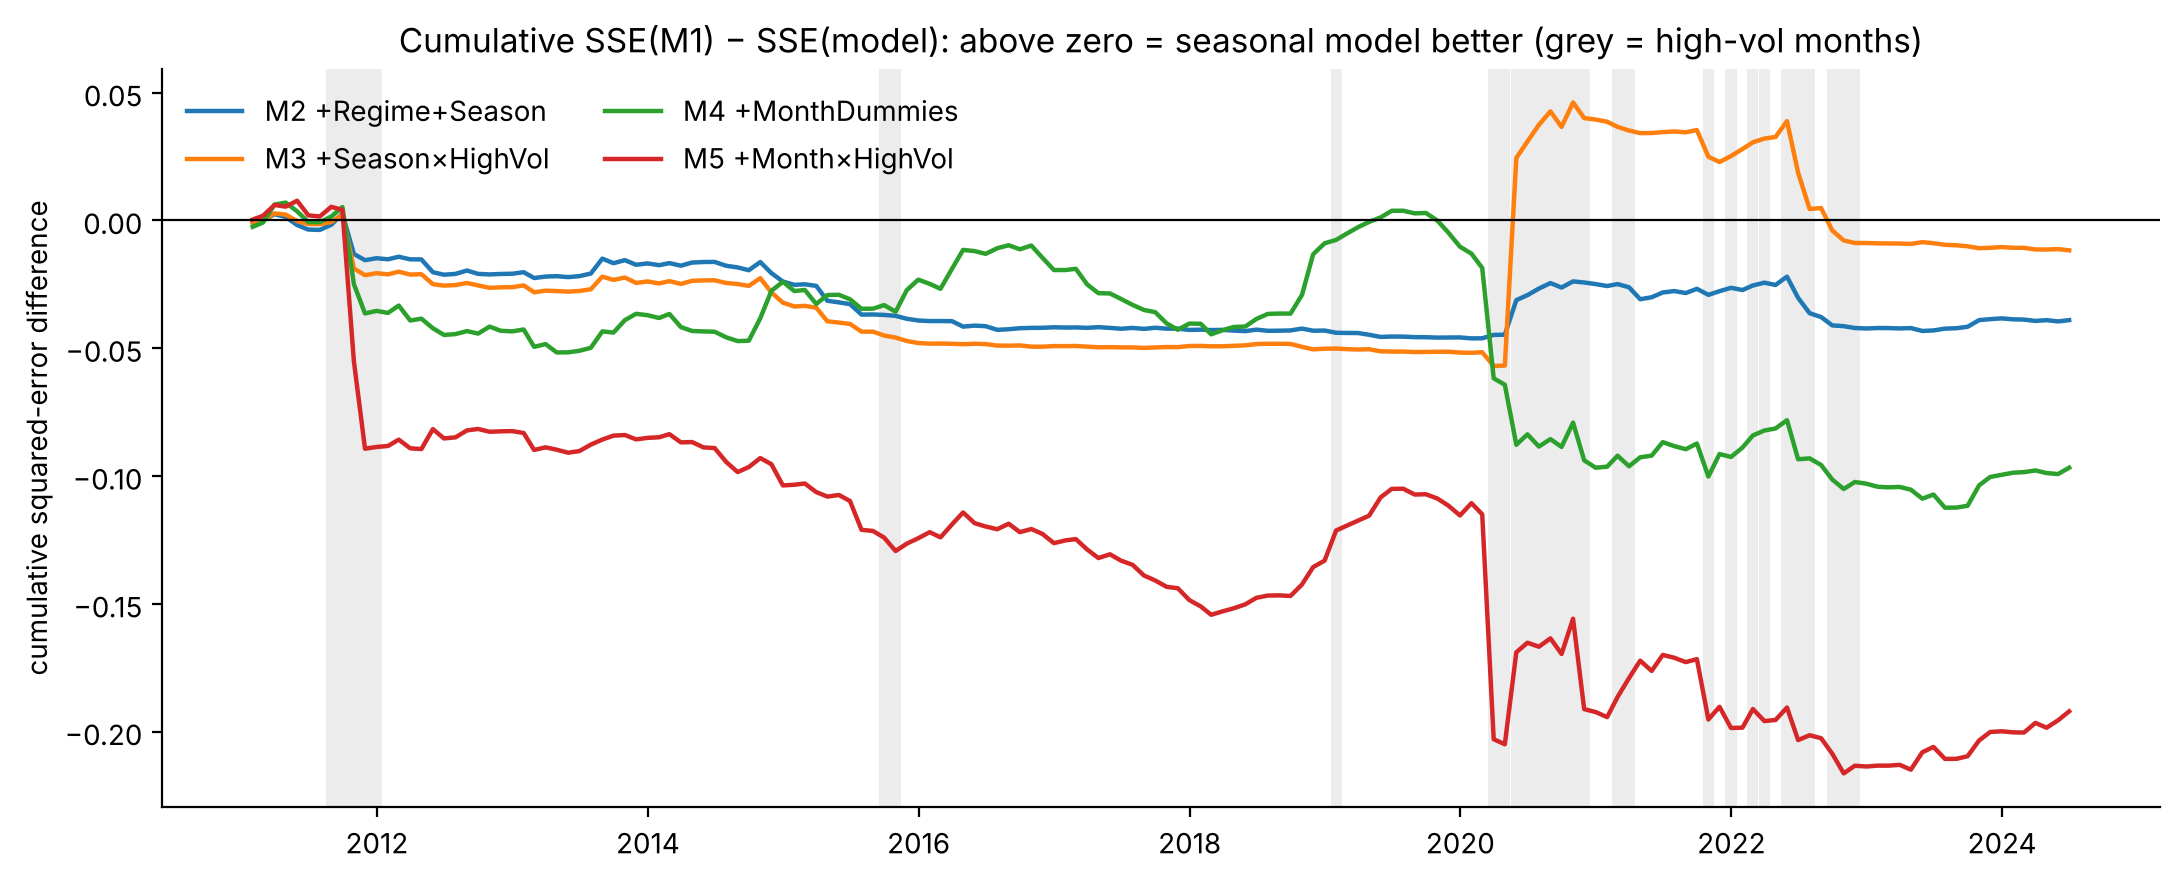

In [15]:
fig, ax = plt.subplots(figsize=(11, 4.5))
for k in list(MODELS)[1:]:
    diff = (fc_main.y - fc_main["M1 Base"]) ** 2 - (fc_main.y - fc_main[k]) ** 2
    ax.plot(fc_main.Date, diff.cumsum(), label=k, lw=1.6)
for dt, hv in zip(fc_main.Date, fc_main.HV):
    if hv: ax.axvspan(dt - pd.Timedelta(days=15), dt + pd.Timedelta(days=15), color="grey", alpha=0.15, lw=0)
ax.axhline(0, color="black", lw=0.8)
ax.set_title("Cumulative SSE(M1) − SSE(model): above zero = seasonal model better (grey = high-vol months)")
ax.set_ylabel("cumulative squared-error difference"); ax.legend(frameon=False, ncol=2)
for s in ["top", "right"]: ax.spines[s].set_visible(False)
plt.tight_layout(); plt.show()

Almost all the movement happens in a few high-vol episodes: **late 2011**, **March–May 2020** (when the front-month contract briefly traded below zero) and **2022**. Between those episodes the seasonal models slowly lose ground.

- **M3** gains a lot in the 2020 crash and gives it back in 2022, ending slightly below zero against M1.
- **M5** (month × high-vol) loses heavily in both 2011 and 2020, which is a sign of overfitting.

#### Robustness checks
1. **COVID excluded.** March–June 2020 is dropped from both training and evaluation.
2. **Later start.** Forecasts begin in 2016 instead of 2011.

Only the **HighVol** rows are shown, since that's the regime the question is about.

In [16]:
robust = {
    "Main (2011 start)":        res_main,
    "Excl. COVID Mar–Jun 2020": evaluate(recursive_forecasts(MODELS, OOS_START, exclude=("2020-03-01", "2020-06-30"))),
    "2016 start":               evaluate(recursive_forecasts(MODELS, pd.Timestamp("2016-01-31"))),
}
summary = pd.concat({k: v[v.Regime == "HighVol"].set_index("Model")[["n", "R2oos_vs_mean", "R2oos_vs_M1", "CW_p_vs_M1"]]
                     for k, v in robust.items()}, axis=1)
summary

Main (2011 start)                                      Excl. COVID Mar–Jun 2020                                      2016 start                                     
                                   n R2oos_vs_mean R2oos_vs_M1 CW_p_vs_M1                        n R2oos_vs_mean R2oos_vs_M1 CW_p_vs_M1          n R2oos_vs_mean R2oos_vs_M1 CW_p_vs_M1
Model                                                                                                                                                                                  
M0 HistMean                       29        0.0000      0.2127        NaN                       25        0.0000      0.1175        NaN         22        0.0000      0.2172        NaN
M1 Base                           29       -0.2701      0.0000        NaN                       25       -0.1332      0.0000        NaN         22       -0.2774      0.0000        NaN
M2 +Regime+Season                 29       -0.2736     -0.0028     0.4831                       25       -0.1864     -0.0470     0.8259         22       -0.2718      0.0044     0.3283
M3 +Season×HighVol                29       -0.2541      0.0126     0.3185                       25       -0.2007     -0.0596     0.7077         22       -0.2435      0.0266     0.2484
M4 +MonthDummies                  29       -0.3737     -0.0816     0.9820                       25       -0.3428     -0.1850     0.8733         22       -0.3572     -0.0625     0.9542
M5 +Month×HighVol                 29       -0.4179     -0.1164     0.8745                       25       -0.5993     -0.4113     0.7778         22       -0.3538     -0.0597     0.7115

**Out-of-sample verdict (Step 2):**
- In high-vol months, M3 (season × high-vol) improves on M1 by only about **1–3%** in R²oos. It's never significant (Clark-West p ≈ 0.25–0.32), and with COVID excluded it turns negative (about −6%).
- The more detailed month-dummy models (M4, M5) are clearly **worse** in high-vol months. They overfit.
- **Every** OLS model has negative R²oos against the historical mean (about −20% to −40%). Unregularised OLS can't beat "forecast the average return".
- The one hint of a positive result is month dummies helping slightly in **low**-vol months, which is the opposite of the hypothesis.

---
## Step 3 — Seasonal terms without the macro base

Step 2's base model forecasts poorly on its own, and that could hide a genuine seasonal signal. Here the macro variables are removed and only regime and seasonal terms are kept. Their forecasts are compared directly with the **historical mean**:

- **S1:** `L1_HighVol + Summer + Winter`
- **S2:** S1 + `Summer_x_HighVol + Winter_x_HighVol`

In [17]:
SEASON_ONLY = {
    "S1 Regime+Season":     ["L1_HighVol", "Summer", "Winter"],
    "S2 S1+Season×HighVol": ["L1_HighVol", "Summer", "Winter", "Summer_x_HighVol", "Winter_x_HighVol"],
}
s3 = pd.concat({start: evaluate(recursive_forecasts(SEASON_ONLY, pd.Timestamp(start)), base=None)
                for start in ["2011-01-31", "2016-01-31"]}, names=["OOS start"])
s3[s3.Regime.isin(["All", "HighVol"]) & (s3.Model != "M0 HistMean")].droplevel(1)[
    ["Regime", "Model", "n", "R2oos_vs_mean", "CW_p_vs_mean"]]

,Regime,Model,n,R2oos_vs_mean,CW_p_vs_mean
OOS start,,,,,
2011-01-31,All,S1 Regime+Season,162,-0.0283,0.9974
2011-01-31,All,S2 S1+Season×HighVol,162,-0.0387,0.9112
2011-01-31,HighVol,S1 Regime+Season,29,-0.0212,0.9956
2011-01-31,HighVol,S2 S1+Season×HighVol,29,-0.0455,0.8052
2016-01-31,All,S1 Regime+Season,102,-0.0129,0.9861
2016-01-31,All,S2 S1+Season×HighVol,102,-0.0160,0.6386
2016-01-31,HighVol,S1 Regime+Season,22,-0.0124,0.9943
2016-01-31,HighVol,S2 S1+Season×HighVol,22,-0.0176,0.5680


Seasonal-only models are slightly **worse** than the historical mean in every case (R²oos about −1% to −5%, Clark-West p > 0.5). Removing the macro base doesn't uncover a hidden seasonal signal.

---
## Conclusion

**Do historical seasonal patterns improve forecasts of WTI front-month returns in high-volatility periods? — No.**

| Evidence | Result |
|---|---|
| In-sample Wald tests (season, season × high-vol, month, month × high-vol) | all p > 0.3 |
| Out-of-sample, high-vol months, M3 vs base | +1.3% R²oos, CW p = 0.32 (not significant) |
| Robustness (COVID excluded / 2016 start) | gain disappears or stays insignificant |
| Seasonal-only vs historical mean | worse in all cases |

High-vol summers do show higher average returns in the raw data. But the effect is small next to return volatility in those months, rests on few observations, and doesn't carry over into better forecasts.

**Limitations:**
- Only 22–29 high-vol months are forecast out-of-sample, so the tests have little power to detect small effects.
- The base model is unstable across training windows.
- The high-vol regime is defined by VIX, an equity-market measure. A volatility measure specific to oil (for example `L1_RV_CL1`) could split the regimes differently.

**Where to go next:**
- Use shrinkage (ridge) on the seasonal interactions, or average forecasts across models.
- Define the regime with oil realised volatility.
- Use daily or weekly data to get more high-vol observations.